# Sección 1 · Entender los datos y definir el problema

**Proyecto:** Predicción mensual de energía en las Zonas No Interconectadas (ZNI) de Colombia
**Fuente de datos:** Telemetría del Centro Nacional de Monitoreo (CNM) del IPSE, publicada en datos.gov.co

### ¿Qué buscamos en esta sección?
Antes de limpiar o modelar, necesitamos responder cuatro preguntas:

1. **¿Qué significa cada columna?** (unidades, tipo y origen)
2. **¿Qué es una fila?** (la *unidad de observación*)
3. **¿Cuánta historia tenemos y qué tan completa está?** Esto decide qué modelos son posibles.
4. **¿Qué vamos a predecir exactamente, y con qué información?**

> Regla de esta sección: **solo observamos y documentamos**. No se corrige nada todavía; las correcciones van en la Sección 2. Así queda claro qué viene de los datos y qué es una decisión nuestra.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FIG = Path("../figuras"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 20); pd.set_option("display.width", 140)

## 1.1 Carga y diccionario de datos

En el proyecto original las columnas se usaban con sus nombres en mayúsculas y con tildes (`'ENERGÍA ACTIVA'`). Funciona, pero da errores con facilidad. Un ejemplo: el notebook original buscaba `'FEHCA DEMANDA MÁXIMA'` (mal escrito), así que ese bloque **nunca se ejecutó** y nadie se dio cuenta.

Aquí renombramos a nombres cortos sin tildes y dejamos escrito qué es cada uno.

In [2]:
raw = pd.read_csv("../datos/raw/energia.csv", encoding="utf-8")
print(raw.shape)
raw.columns.tolist()

(3294, 14)


['ID DEPATAMENTO',
 'DEPARTAMENTO',
 'ID MUNICIPIO',
 'MUNICIPIO',
 'ID LOCALIDAD',
 'LOCALIDAD',
 'AÑO SERVICIO',
 'MES SERVICIO',
 'ENERGÍA ACTIVA',
 'ENERGÍA REACTIVA',
 'POTENCIA MÁXIMA',
 'DÍA DE DEMANDA MÁXIMA',
 'FECHA DE DEMANDA MÁXIMA',
 'PROMEDIO DIARIO EN HORAS']

In [3]:
RENOMBRE = {
    "ID DEPATAMENTO": "id_depto", "DEPARTAMENTO": "depto",
    "ID MUNICIPIO": "id_mpio", "MUNICIPIO": "mpio",
    "ID LOCALIDAD": "id_loc", "LOCALIDAD": "localidad",
    "AÑO SERVICIO": "anio", "MES SERVICIO": "mes",
    "ENERGÍA ACTIVA": "e_activa", "ENERGÍA REACTIVA": "e_reactiva",
    "POTENCIA MÁXIMA": "pot_max", "DÍA DE DEMANDA MÁXIMA": "dia_dmax",
    "FECHA DE DEMANDA MÁXIMA": "fecha_dmax", "PROMEDIO DIARIO EN HORAS": "horas_dia",
}
df = raw.rename(columns=RENOMBRE)
df["fecha"] = pd.to_datetime(dict(year=df.anio, month=df.mes, day=1))
df["fecha_dmax"] = pd.to_datetime(df.fecha_dmax, format="%m/%d/%Y %I:%M:%S %p")
df.head()

,id_depto,depto,id_mpio,mpio,id_loc,localidad,anio,mes,e_activa,e_reactiva,pot_max,dia_dmax,fecha_dmax,horas_dia,fecha
0,91,AMAZONAS,91001,LETICIA,91001000,LETICIA (LETICIA - AMAZONAS),2020,1,3930642,1251191,7768.76,lunes,2020-01-27 14:15:00,24.00,2020-01-01
1,91,AMAZONAS,91540,PUERTO NARIÑO,91540000,PUERTO NARIÑO (PUERTO NARIÑO - AMAZONAS),2020,1,103897,36304,227.04,miércoles,2020-01-22 19:15:00,24.00,2020-01-01
2,91,AMAZONAS,91798,TARAPACÁ (ANM),91798000,TARAPACÁ (TARAPACÁ (ANM) - AMAZONAS),2020,1,22864,9277,88.96,jueves,2020-01-30 19:30:00,10.19,2020-01-01
3,5,ANTIOQUIA,5873,VIGÍA DEL FUERTE,5873001,SAN ANTONIO DE PADUA (VIGÍA DEL FUERTE - ANTIO...,2020,1,5617,1381,53.66,jueves,2020-01-23 19:45:00,4.13,2020-01-01
4,5,ANTIOQUIA,5873,VIGÍA DEL FUERTE,5873002,VEGÁEZ (VIGÍA DEL FUERTE - ANTIOQUIA),2020,1,2217,539,39.07,miércoles,2020-01-29 19:45:00,3.17,2020-01-01


| Columna | Tipo | Unidad | Qué significa | ¿Sirve para predecir? |
|---|---|---|---|---|
| `id_depto`, `depto` | identificador | – | Departamento (código DANE) | Como contexto (agrupar) |
| `id_mpio`, `mpio` | identificador | – | Municipio (código DANE) | Como contexto |
| `id_loc`, `localidad` | identificador | – | Localidad: el sistema de generación aislado. **Es la entidad que pronosticamos** | Es la clave de la serie |
| `anio`, `mes` → `fecha` | tiempo | mes | Mes de servicio | Es el eje del tiempo |
| `e_activa` | numérica | kWh/mes | Energía útil entregada en el mes | **Variable objetivo** |
| `e_reactiva` | numérica | kVArh/mes | Energía reactiva (no produce trabajo útil) | Solo con rezago (mes anterior) |
| `pot_max` | numérica | kW | Pico de demanda del mes | Solo con rezago |
| `dia_dmax`, `fecha_dmax` | fecha/categoría | – | Cuándo ocurrió el pico | Poco útil para lo mensual |
| `horas_dia` | numérica | h/día | Horas promedio de servicio al día (0–24) | Solo con rezago |

**La idea clave de la última columna:** cuando pronosticamos la energía de *marzo*, todavía no conocemos la potencia máxima ni las horas de *marzo*, porque se miden en el mismo mes. Solo podemos usar lo que ya pasó: febrero, enero, etc. Si se usan variables del mismo mes, el modelo "hace trampa". En inglés esto se llama *data leakage* (fuga de información).

## 1.2 ¿Qué es una fila?

Hipótesis: **cada fila = una localidad en un mes**. Si es cierto, la pareja (`id_loc`, `fecha`) no debería repetirse.

In [4]:
print("Filas:", len(df))
print("Duplicados (localidad, mes):", df.duplicated(["id_loc", "fecha"]).sum())
print("Valores nulos en total:", df.isna().sum().sum())
print("Localidades:", df.id_loc.nunique(), "| Municipios:", df.id_mpio.nunique(), "| Departamentos:", df.depto.nunique())
print("Periodo:", df.fecha.min().date(), "→", df.fecha.max().date(), "=", df.fecha.nunique(), "meses")

Filas: 3294
Duplicados (localidad, mes): 0
Valores nulos en total: 0
Localidades: 133 | Municipios: 51 | Departamentos: 18
Periodo: 2020-01-01 → 2023-06-01 = 42 meses


Se confirma: **133 series de tiempo mensuales** (una por localidad) entre enero de 2020 y junio de 2023.

Este es un **panel de datos**: muchas entidades observadas en el tiempo. No es una tabla de casos independientes. Eso tiene una consecuencia directa:

> ❌ `train_test_split(..., random_state=42)` (lo que hacía el notebook original) mezcla meses al azar. El modelo termina entrenando con junio de 2023 para "predecir" marzo de 2020.
> ✅ En series de tiempo se entrena con el **pasado** y se evalúa con el **futuro**. Lo construimos en la Sección 4.

Además, en la tabla de arriba no hay nulos. El `fillna(0)` y el `dropna()` del notebook original no hacían nada. Y aunque hubiera habido nulos, rellenar energía con 0 sería un error: un dato faltante no significa "no hubo consumo".

## 1.3 ¿Cuánta historia tenemos?

Es la pregunta más importante para elegir el modelo. Un SARIMA estacional necesita idealmente 3 o más años **por serie**; con 1 o 2 años no puede aprender bien la estacionalidad.

In [5]:
g = df.groupby("id_loc").agg(localidad=("localidad", "first"), depto=("depto", "first"),
                             n_meses=("fecha", "nunique"), inicio=("fecha", "min"), fin=("fecha", "max"),
                             e_media=("e_activa", "mean"))
g["span"] = (g.fin.dt.year - g.inicio.dt.year) * 12 + (g.fin.dt.month - g.inicio.dt.month) + 1
g["huecos"] = g.span - g.n_meses
g[["n_meses", "span", "huecos"]].describe().round(1)

,n_meses,span,huecos
count,133.0,133.0,133.0
mean,24.8,28.3,3.6
std,14.3,15.2,4.4
min,1.0,1.0,0.0
25%,11.0,16.0,0.0
50%,29.0,34.0,2.0
75%,38.0,42.0,6.0
max,42.0,42.0,23.0


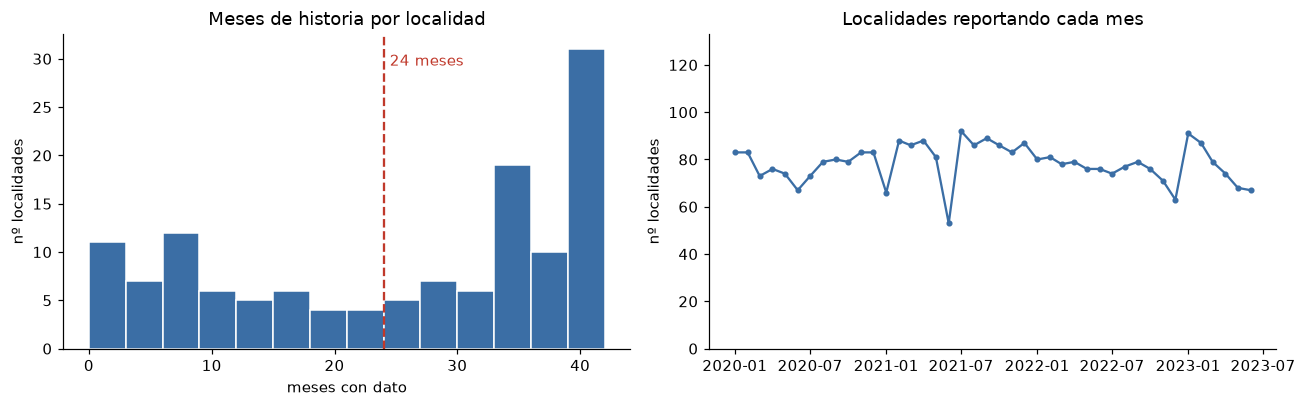

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(g.n_meses, bins=range(0, 44, 3), color="#3b6ea5", edgecolor="white")
ax[0].axvline(24, color="#c0392b", ls="--"); ax[0].text(24.5, ax[0].get_ylim()[1]*0.9, "24 meses", color="#c0392b")
ax[0].set(title="Meses de historia por localidad", xlabel="meses con dato", ylabel="nº localidades")
por_mes = df.groupby("fecha").id_loc.nunique()
ax[1].plot(por_mes.index, por_mes.values, marker="o", ms=3, color="#3b6ea5")
ax[1].set(title="Localidades reportando cada mes", ylabel="nº localidades", ylim=(0, 133))
fig.tight_layout(); fig.savefig(FIG / "s1_cobertura.png"); plt.show()

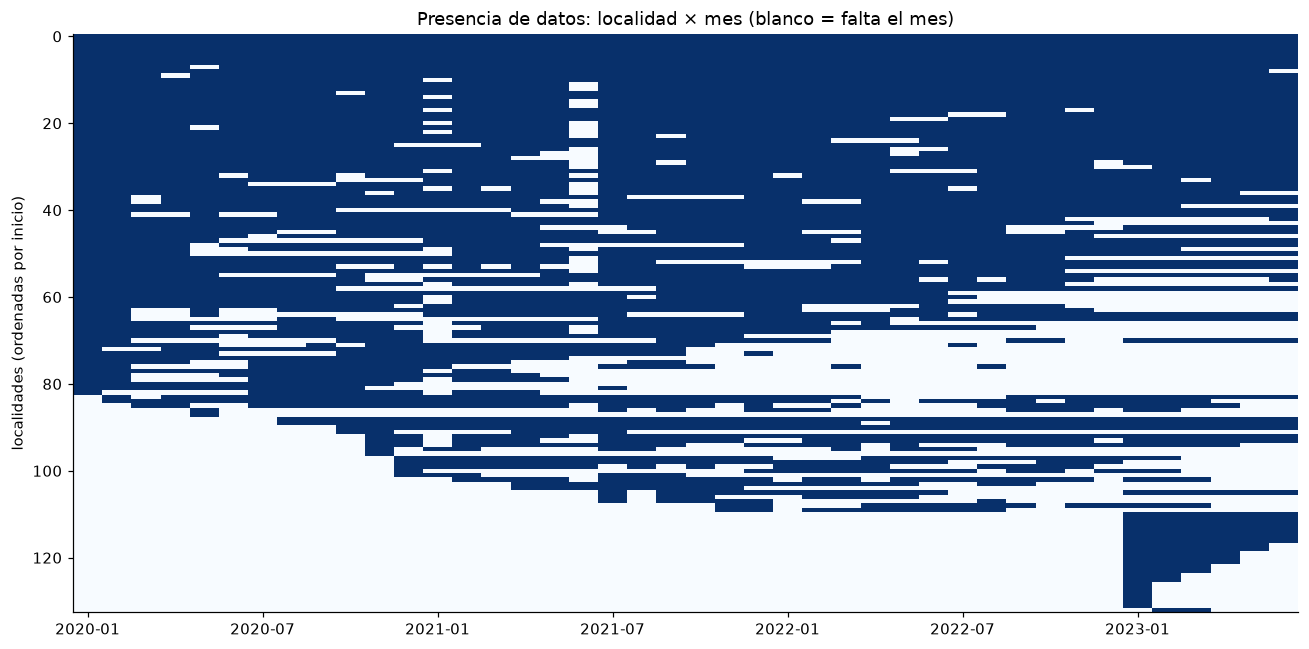

In [7]:
# Mapa de presencia: cada fila es una localidad y cada columna un mes (oscuro = hay dato)
pres = (df.assign(v=1).pivot_table(index="id_loc", columns="fecha", values="v", fill_value=0))
orden = g.sort_values(["inicio", "n_meses"], ascending=[True, False]).index
fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(pres.loc[orden].values, aspect="auto", cmap="Blues", interpolation="nearest")
ax.set_xticks(range(0, 42, 6)); ax.set_xticklabels([d.strftime("%Y-%m") for d in pres.columns[::6]])
ax.set(title="Presencia de datos: localidad × mes (blanco = falta el mes)", ylabel="localidades (ordenadas por inicio)")
fig.tight_layout(); fig.savefig(FIG / "s1_mapa_presencia.png"); plt.show()

In [8]:
umbrales = [12, 24, 30, 36, 42]
pd.DataFrame({"min_meses": umbrales,
              "localidades": [(g.n_meses >= u).sum() for u in umbrales],
              "% energía total": [round(100 * df[df.id_loc.isin(g.index[g.n_meses >= u])].e_activa.sum() / df.e_activa.sum(), 1) for u in umbrales]})

,min_meses,localidades,% energía total
0,12,97,99.9
1,24,78,99.1
2,30,66,98.9
3,36,41,85.0
4,42,7,2.1


**Interpretación:**
- La localidad típica tiene **29 meses** de datos, y **93 de las 133 tienen huecos** (meses sin reporte en medio de su historia).
- Solo **7 localidades** tienen los 42 meses completos.
- Muchas localidades **entran o salen** del sistema de monitoreo a mitad del periodo. El mapa de presencia lo muestra.
- Aun así, las localidades con 24 meses o más concentran casi toda la energía (ver la tabla).

**Consecuencia para el modelo:** un modelo independiente por localidad (por ejemplo un SARIMA para cada una) tiene muy poca historia. Lo que recomienda la literatura (Montero-Manso & Hyndman, 2021) para muchas series cortas es un **modelo global**: un solo modelo que aprende de todas las localidades al mismo tiempo. Lo compararemos contra modelos simples por localidad.

## 1.4 ¿Quién consume la energía? (concentración)

,% energía
localidad,
SAN ANDRÉS (SAN ANDRÉS - ARCHIPIÉLAGO DE SAN ANDRÉS Y PROVIDENCIA),50.9
LETICIA (LETICIA - AMAZONAS),11.9
PUERTO CARREÑO (PUERTO CARREÑO - VICHADA),8.1
INÍRIDA (INÍRIDA - GUAINÍA),4.7
MITÚ (MITÚ - VAUPÉS),4.4
PROVIDENCIA (PROVIDENCIA - ARCHIPIÉLAGO DE SAN ANDRÉS Y PROVIDENCIA),2.8
PUERTO LEGUÍZAMO (PUERTO LEGUÍZAMO - PUTUMAYO),2.4
ACANDÍ (ACANDÍ - CHOCÓ),1.8


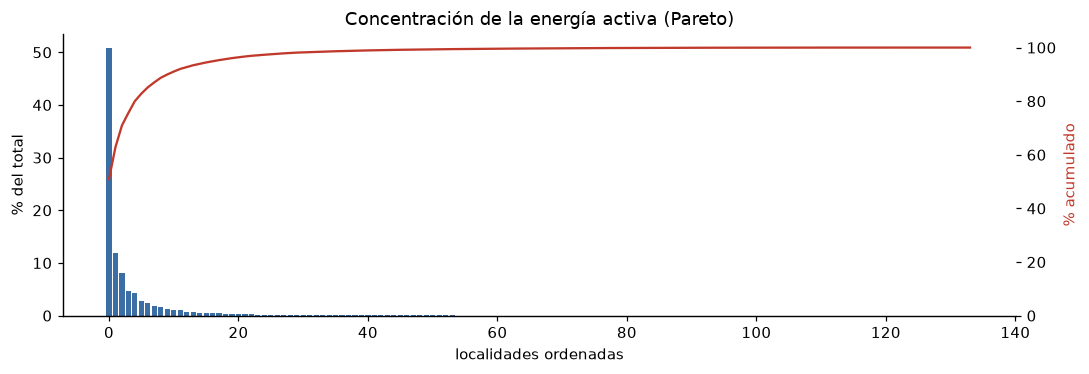

In [9]:
tot = df.groupby("localidad").e_activa.sum().sort_values(ascending=False)
share = (tot / tot.sum() * 100)
display(share.head(8).round(1).to_frame("% energía"))
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(range(len(share)), share.values, color="#3b6ea5")
ax2 = ax.twinx(); ax2.plot(range(len(share)), share.cumsum().values, color="#c0392b"); ax2.set_ylim(0, 105)
ax2.set_ylabel("% acumulado", color="#c0392b"); ax2.spines["top"].set_visible(False)
ax.set(title="Concentración de la energía activa (Pareto)", xlabel="localidades ordenadas", ylabel="% del total")
fig.tight_layout(); fig.savefig(FIG / "s1_pareto.png"); plt.show()

**San Andrés representa el 51 % de toda la energía** y las 5 primeras localidades el 80 %. Las otras ~128 son pueblos pequeños, con consumos entre decenas y miles de kWh al mes.

**Consecuencias:**
1. Si pronosticamos el **total** de las ZNI, en la práctica estamos pronosticando San Andrés. Por eso trabajamos **por localidad**.
2. Un error de 1.000 kWh es insignificante en San Andrés y enorme en una vereda del Chocó. Para comparar localidades usaremos métricas **relativas a la escala** (MAPE/sMAPE, MASE), no solo el MAE en kWh.
3. Las gráficas de torta del notebook original (porcentaje por departamento) sobre todo reflejaban "San Andrés contra el resto".

## 1.5 Forma de las series: ejemplos de distintos tamaños

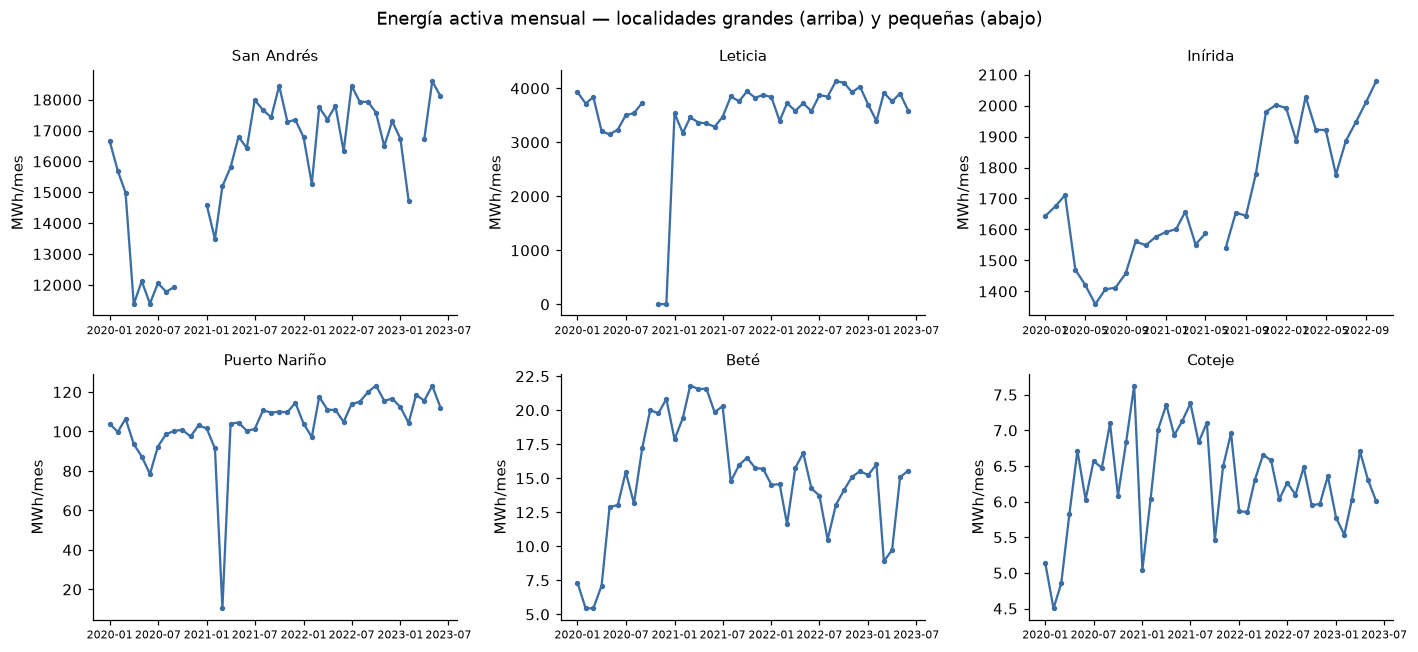

In [10]:
ejemplos = ["SAN ANDRÉS", "LETICIA", "INÍRIDA", "PUERTO NARIÑO", "BETÉ", "COTEJE"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, nombre in zip(axes.flat, ejemplos):
    s = df[df.localidad.str.startswith(nombre)].sort_values("fecha")
    s = s.set_index("fecha").e_activa.asfreq("MS")  # asfreq deja visibles los huecos (NaN)
    ax.plot(s.index, s.values / 1000, marker="o", ms=2.5, color="#3b6ea5")
    ax.set_title(nombre.title(), fontsize=10); ax.set_ylabel("MWh/mes"); ax.tick_params(axis="x", labelsize=7)
fig.suptitle("Energía activa mensual — localidades grandes (arriba) y pequeñas (abajo)")
fig.tight_layout(); fig.savefig(FIG / "s1_series_ejemplo.png"); plt.show()

**Qué se observa** (lo cuantificamos en la Sección 3):
- Las localidades **grandes** tienen series suaves, con tendencia y algo de estacionalidad. Son "pronosticables".
- Las **pequeñas** tienen saltos bruscos: meses con caída a casi cero (fallas, falta de combustible) y cambios de nivel. Ahí el patrón depende más de la operación del sistema (cuántas horas se presta el servicio) que del consumo de la gente.
- Los cortes en las líneas son **meses faltantes**. No son ceros.
- **Efecto COVID-19:** San Andrés cae de ~16.000 a ~12.000 MWh/mes entre abril y diciembre de 2020 (cierre del turismo). Es un cambio **real**, pero excepcional. Si el modelo aprende de 2020 como si fuera un año normal, va a distorsionar la estacionalidad. Lo tratamos en las Secciones 2 y 3.
- **Caídas sospechosas a casi cero:** Leticia en noviembre de 2020 reporta 2.925 kWh cuando su nivel normal es de ~3.500.000, con una potencia de 20 kW en lugar de ~7.000. Parece un registro de otra localidad o un error de digitación, no un apagón de una ciudad entera.

## 1.6 Problemas de calidad detectados (solo se documentan)

Se marcan con una bandera y se tratan en la Sección 2.

In [11]:
d = df.copy()
med_pot = d.groupby("id_loc").pot_max.transform("median")
dias = d.fecha.dt.days_in_month
flags = {
    "energía = 0": d.e_activa == 0,
    "horas = 0 pero energía > 0": (d.horas_dia == 0) & (d.e_activa > 0),
    "pot_max > 50× su mediana (¿error de unidades W vs kW?)": d.pot_max > 50 * med_pot,
    "energía imposible: E > pot_max × horas × días": d.e_activa > 1.05 * d.pot_max * d.horas_dia * dias,
    "caída > 90 % frente a la mediana de su localidad": (d.e_activa > 0) & (d.e_activa < 0.1 * d.groupby("id_loc").e_activa.transform("median")),
}
resumen = pd.DataFrame({k: [v.sum()] for k, v in flags.items()}, index=["filas"]).T
display(resumen)
d.loc[flags["pot_max > 50× su mediana (¿error de unidades W vs kW?)"],
      ["localidad", "fecha", "e_activa", "pot_max", "horas_dia"]].assign(mediana_pot=med_pot)

,filas
energía = 0,15
horas = 0 pero energía > 0,3
pot_max > 50× su mediana (¿error de unidades W vs kW?),29
energía imposible: E > pot_max × horas × días,13
caída > 90 % frente a la mediana de su localidad,17


,localidad,fecha,e_activa,pot_max,horas_dia,mediana_pot
263,CAPURGANÁ (ACANDÍ - CHOCO),2020-04-01,212215,47027.00,19.60,818.400
339,CAPURGANÁ (ACANDÍ - CHOCO),2020-05-01,220933,48259.00,19.70,818.400
546,NOANAMITO (LÓPEZ DE MICAY - CAUCA),2020-08-01,7421,4800.00,8.27,44.000
559,EL VALLE (BAHÍA SOLANO - CHOCÓ),2020-08-01,141003,29700.00,23.51,333.300
565,BETÉ (MEDIO ATRATO (BETÉ) - CHOCÓ),2020-08-01,13147,7600.00,8.41,64.000
580,SAN JOSÉ DEL TAPAJE (EL CHARCO - NARIÑO),2020-08-01,15410,8800.00,7.29,80.000
589,PITAL DE LA COSTA (TUMACO - NARIÑO),2020-08-01,20520,7600.00,11.70,88.000
635,CAPURGANÁ (ACANDÍ - CHOCO),2020-09-01,211904,45654.00,20.15,818.400
645,BETÉ (MEDIO ATRATO (BETÉ) - CHOCÓ),2020-09-01,17201,7200.00,11.12,64.000
703,NOANAMITO (LÓPEZ DE MICAY - CAUCA),2020-10-01,6812,3600.00,8.34,44.000


In [12]:
# Inconsistencia de nombres: misma localidad con nombre escrito distinto
print(df.groupby("id_loc").localidad.nunique().gt(1).sum(), "localidades con más de un nombre")
df[df.localidad.str.contains("CHOCO\\)", regex=True)].localidad.unique()

1 localidades con más de un nombre


<StringArray>
['CAPURGANÁ (ACANDÍ - CHOCO)', 'PUERTO CONTO (BOJAYÁ (BELLAVISTA) - CHOCO)', 'ARUSÍ (NUQUÍ - CHOCO)', 'SIPÍ (SIPÍ - CHOCO)']
Length: 4, dtype: str

**Hallazgos:**
- **Errores de digitación o unidades en `pot_max` (29 filas):** San Andrés en abril de 2021 reporta 2.694.319 kW cuando lo normal ronda los 2.700 kW (~1000×, probablemente **W en lugar de kW**). Varias veredas en agosto de 2020 tienen valores ~100× su nivel normal (por ejemplo 4.800 contra 44 kW), lo que parece un **separador decimal perdido**. Que muchas caigan en el mismo mes sugiere un problema en la carga de ese reporte.
- **Leticia en marzo y abril de 2021 reporta 0 horas de servicio**, pero más de 3 millones de kWh. Es un error de registro en `horas_dia`.
- **Filas físicamente imposibles:** la energía supera lo que permiten la potencia máxima y las horas. Son casi todas de veredas muy pequeñas.
- **15 meses con energía = 0:** pueden ser un apagón real (el sistema no operó) o un dato mal registrado. Hay que decidir qué hacer con ellos (Sección 2).
- **Caídas abruptas de energía** (> 90 % por debajo de lo normal de la localidad): hay que separar los apagones reales de los errores de registro, como el caso de Leticia.
- Nombres con distinta escritura ("CHOCO" sin tilde) y una localidad que aparece con dos nombres. Por eso **siempre se agrupa por `id_loc`, nunca por el nombre**.

Ninguno de estos problemas aparece con `isnull()` ni con `drop_duplicates()`, que era todo lo que revisaba el notebook original.

## 1.7 ¿Por qué el modelo original daba MAE = 0,70? La relación horas ↔ energía/potencia

El notebook original predecía `PROMEDIO DIARIO EN HORAS` usando `ENERGÍA ACTIVA` y `POTENCIA MÁXIMA` **del mismo mes**. Por física, la energía de un mes es:

$$E_{mes} \approx P_{max} \times FC \times h_{día} \times días$$

donde $FC$ es el *factor de carga*: qué tan cerca del pico opera el sistema en promedio. Si despejamos:

$$h_{día} \approx \frac{E_{mes}}{P_{max}\cdot FC \cdot días}$$

Es decir, **las horas casi se calculan a partir de las otras dos variables**. El modelo no estaba prediciendo nada: estaba reconstruyendo una fórmula con datos del mismo mes, que en un pronóstico real no se conocen.

Correlación horas reales vs E/(P·días): 0.973
Factor de carga típico (mediana): 0.75


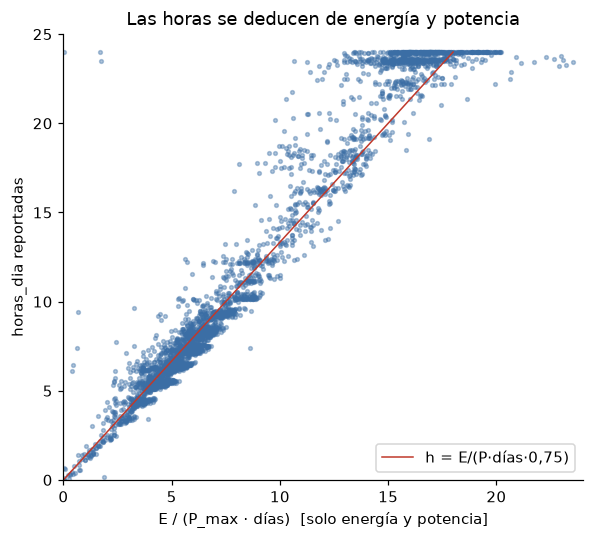

In [13]:
ok = (d.pot_max > 0) & (d.horas_dia > 0) & ~flags["pot_max > 50× su mediana (¿error de unidades W vs kW?)"]
d["h_formula"] = d.e_activa / (d.pot_max * dias)          # horas implícitas con FC = 1
d["fc"] = d.e_activa / (d.pot_max * d.horas_dia * dias)    # factor de carga implícito
print("Correlación horas reales vs E/(P·días):", round(d.loc[ok, ["horas_dia", "h_formula"]].corr().iloc[0, 1], 3))
print("Factor de carga típico (mediana):", round(d.loc[ok, "fc"].median(), 2))

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(d.loc[ok, "h_formula"], d.loc[ok, "horas_dia"], s=6, alpha=0.4, color="#3b6ea5")
x = np.linspace(0, 24, 10); ax.plot(x * 0.75, x, color="#c0392b", lw=1, label="h = E/(P·días·0,75)")
ax.set(xlim=(0, 24), ylim=(0, 25), xlabel="E / (P_max · días)  [solo energía y potencia]", ylabel="horas_dia reportadas",
       title="Las horas se deducen de energía y potencia")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "s1_horas_formula.png"); plt.show()

Con una correlación de ~0,97 y un factor de carga bastante estable (~0,75), cualquier modelo que reciba `E` y `P` del mismo mes "adivina" las horas casi perfectamente. Eso explica el MAE de 0,70 del Random Forest original. **No es un mérito del modelo**: es la ecuación de arriba.

La regresión lineal original daba MAE = 5,93 porque la relación es una **división** (no lineal), y además la lista de variables tenía `ENERGÍA ACTIVA` repetida dos veces.

## 1.8 Definición del problema (la decisión de esta sección)

| Elemento | Proyecto original | **Proyecto nuevo** |
|---|---|---|
| Pregunta | Predecir horas de servicio (no estaba explícito) | **¿Cuánta energía activa (kWh) consumirá cada localidad de las ZNI en los próximos meses?** |
| Variable objetivo | `PROMEDIO DIARIO EN HORAS` | **`e_activa`** (kWh/mes) |
| Unidad de pronóstico | Fila suelta | **Localidad × mes** (133 series) |
| Horizonte | No había (no era pronóstico) | **1 mes adelante** (principal) y **3 meses** (secundario) |
| Información permitida | Variables del mismo mes (fuga) | **Solo información del pasado**: rezagos de energía, potencia, horas; mes del año; datos de la localidad |
| Validación | Partición aleatoria 80/20 | **Temporal**: entrenar hasta una fecha y evaluar los meses siguientes (Sección 4) |
| Métricas | MAE, RMSE | **MAE, RMSE + sMAPE y MASE** (comparables entre localidades de distinto tamaño) |
| Referencia mínima | Ninguna | **Modelo ingenuo**: "igual que el mes pasado" y "igual que hace 12 meses". Un modelo solo vale si les gana |

**¿Por qué 1 y 3 meses?** El IPSE y los operadores planifican el combustible (diésel) y el mantenimiento mes a mes. Además, con 42 meses de historia, un horizonte de 12 meses dejaría casi nada para evaluar.

**¿Y `horas_dia`?** No se descarta: será una **variable explicativa con rezago**. Si el mes pasado hubo pocas horas de servicio, eso ayuda a anticipar la energía de este mes. Pero no es el objetivo.

In [14]:
# Guardamos el dataset con nombres limpios (SIN correcciones todavía) para la Sección 2
Path("../datos/interim").mkdir(parents=True, exist_ok=True)
df.to_csv("../datos/interim/s1_renombrado.csv", index=False)
g.to_csv("../datos/interim/s1_resumen_localidades.csv")
print("Guardado:", len(df), "filas |", len(g), "localidades")

Guardado:

 3294 filas | 133 localidades


## Resumen de la Sección 1

1. Los datos son un **panel de 133 series mensuales cortas** (mediana de 29 meses), con huecos y con localidades que entran y salen.
2. La energía está **muy concentrada** (San Andrés 51 %), así que se pronostica y evalúa **por localidad**, con métricas relativas.
3. Hay **errores de registro** que el análisis original no detectó: unidades de potencia, horas en 0, energía imposible y caídas sospechosas. También hay un **choque externo real (COVID-19, 2020)**.
4. El modelo original **no pronosticaba**: reconstruía `horas ≈ E/(P·FC·días)` con datos del mismo mes.
5. **Nuevo problema:** pronosticar `e_activa` de cada localidad a 1 y 3 meses, usando solo el pasado y con validación temporal.

**Siguiente — Sección 2 (limpieza):** decidir qué hacer con cada bandera de la sección 1.6. Corregir, marcar o excluir, con una regla escrita para cada caso.